In [148]:
# !uv pip install --system scikit-learn==1.5.2

try:
    from autogluon.tabular import TabularPredictor
except:
    !uv pip install autogluon
    from autogluon.tabular import TabularPredictor

## -- To use Foundation models: data ~100k rows --
!uv pip install autogluon.tabular[tabarena]

Using Python 3.12.13 environment at: /usr
Checked 1 package in 242ms


In [149]:
# %%capture saved_prints
!uv pip install ipywidgets
!apt-get install -qq -y graphviz graphviz-dev && pip install -q pydot
!pip install -qq pygraphviz

Using Python 3.12.13 environment at: /usr
Checked 1 package in 182ms


In [150]:
## -- System dependencies --
import sys, os, gc
import torch

## -- Device-Agnostic (GPU/CPU) --
def get_system_info():
    if torch.cuda.is_available():
        return f"GPU: {torch.cuda.get_device_name(0)}"
    else:
        return f"CPU: {os.cpu_count()}"

get_system_info()

'CPU: 4'

In [151]:
%matplotlib inline
%config InlineBackend.figure_format = 'svg'

In [152]:
import random
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Image

from tqdm.auto import tqdm
from time import time, sleep
import itertools

try:
    from colorama import Fore, Style
except:
    !pip install -q colorama
    from colorama import Fore, Style

import warnings

## -- Global Settings --
# sklearn.set_config(transform_output="pandas")
warnings.simplefilter('ignore')
warnings.filterwarnings('ignore')

# pd.options.mode.copy_on_write = True
pd.set_option('display.max_columns', 100)
# plt.style.use("ggplot")

In [153]:
TEAL, GOLD, CORAL, BLUE, DARK, CRIM, MUTED, INK, PAPER = '#168c91','#e8b44f','#dc705a',\
                                                         'dodgerblue','#0B4F7A','crimson',\
                                                         '#627D98','#102A43','#faf9f5'
plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': PAPER,
    'savefig.facecolor': PAPER,
    'font.family': 'DejaVu Sans',
    'font.size': 9,
    'axes.titlesize': 12,
    'axes.titleweight': 'semibold',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': DARK,
    'ytick.color': DARK,
    'axes.edgecolor': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.color': MUTED,
    'patch.edgecolor': DARK,
    # 'patch.force_edgecolor': True,
    # 'patch.linewidth': 1.5,
    # 'figure.dpi':110,
    # 'savefig.dpi':160,
})
# CMAP = LinearSegmentedColormap.from_list('atlas', ['#f0f5ef','#a9d6ca',TEAL,INK])
sns.set_palette([TEAL, GOLD, CORAL, BLUE, MUTED, CRIM, DARK, INK, PAPER])

## -- Set Global Seed --
CFG = {
    'FOLDS':  5,
    'SEED':   42,
    'GREEN':  '\033[32m',
    'YELLOW': '\033[33m',
    'RESET':  '\033[0m'
}

print(f"CLASSIC {CFG['GREEN']} GREEN {CFG['RESET']} {CFG['YELLOW']} YELLOW {CFG['RESET']}")

CLASSIC  GREEN   YELLOW 


In [154]:
## -- ⚠️ IMPORTANT: SELECT PLATFORM ⚠️ --
PLATFORM = "kaggle" # -> 'colab' 'kaggle'

if PLATFORM == "kaggle":
    PATH = "/kaggle/input/competitions/playground-series-s6e10/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train = pd.read_csv(PATH+"train.csv")
    test = pd.read_csv(PATH+"test.csv")

    ORIG_PATH = "/kaggle/input/datasets/arseniyshutko/binary-aviation-satisfaction-129k/"
    orig = pd.read_csv(ORIG_PATH+"data.csv")
elif PLATFORM == "colab":
    from google.colab import drive
    drive.mount("/content/drive")

    PATH   = "/content/drive/MyDrive/-- shared_notebooks --/Ps6e10 | Airline Satisfaction/_airline_data/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    orig   = pd.read_csv(PATH+"data.csv")

## =================================================================================

TARGET, ID = 'satisfaction', 'id'

train[TARGET] = train[TARGET].map({True: 1, False: 0})
orig[TARGET] = orig[TARGET].map({True: 1, False: 0})

obj = train.select_dtypes(include=["object", "category"]).columns.tolist()

cat_cols  = [c for c in obj if c not in [TARGET, ID]]
num_cols  = [c for c in train.columns if c not in cat_cols+[TARGET, ID]]
base_cols = [c for c in train.columns if c not in [TARGET, ID]]

service_cols = [
    'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking',
    'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
    'Inflight entertainment', 'On-board service', 'Leg room service',
    'Baggage handling', 'Checkin service', 'Cleanliness'
]

train = train[base_cols+[TARGET]]
orig  = orig[base_cols+[TARGET]]
test  = test[base_cols]

print(f"Frame type: {type(train)}\n")

for (name, df) in {"Train": train, "Test": test, 'Orig': orig}.items(): #
    print(f"{name} shape: {df.shape}")

print(f"Total Numerical: {len(num_cols)}")
print(f"Total Categorical: {len(cat_cols)}")
print(f"Total base features: {len(base_cols)}")

Frame type: <class 'pandas.core.frame.DataFrame'>

Train shape: (699635, 22)
Test shape: (299844, 21)
Orig shape: (129880, 22)
Total Numerical: 17
Total Categorical: 4
Total base features: 21


In [155]:
train['Arrival Delay in Minutes'] = train['Arrival Delay in Minutes'].fillna(0.0)
test['Arrival Delay in Minutes']  = test['Arrival Delay in Minutes'].fillna(0.0)
orig['Arrival Delay in Minutes']  = orig['Arrival Delay in Minutes'].fillna(0.0)

In [156]:
train.head()

,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0
1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,1
2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0
3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,0
4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,0


In [157]:
!rm -r /kaggle/working

MODELS_PATH = "/kaggle/working/ag_Flight_models/"
# !rm -r {MODELS_PATH}

rm: cannot remove '/kaggle/working': Device or resource busy


In [158]:
## -- RUN 1: Use train data -- 
feat_TARGET = "Seat comfort"

predictor = TabularPredictor(
            label = feat_TARGET,
     # problem_type = "regression",
      # eval_metric = 'roc_auc',
             path = MODELS_PATH,
).fit(
           train_data = orig.drop(columns=[TARGET]),
              presets = "best_quality_v150", # v1_original_best_quality_v150
        num_bag_folds = 4,
     dynamic_stacking = False,
     num_stack_levels = 1, # 0 if False
           time_limit = 3600,
           auto_stack = False,
         # num_bag_sets = 2,
          # ag_args_fit = {'num_cpus': os.cpu_count()},
)

Verbosity: 2 (Standard Logging)
=================== System Info ===================
AutoGluon Version:  1.6.3
Python Version:     3.12.13
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #1 SMP Thu Oct 22 16:37:21 UTC 2026
CPU Count:          4
Pytorch Version:    2.10.0+cpu
CUDA Version:       CUDA is not available
Memory Avail:       27.34 GB / 31.35 GB (87.2%)
Disk Space Avail:   19.50 GB / 19.52 GB (99.9%)
Presets specified: ['best_quality_v150']
Using hyperparameters preset: hyperparameters='zeroshot_2025_12_18_cpu'
Beginning AutoGluon training ... Time limit = 3600s
AutoGluon will save models to "/kaggle/working/ag_Flight_models"
Train Data Rows:    129880
Train Data Columns: 20
Label Column:       Seat comfort
AutoGluon infers your prediction problem is: 'multiclass' (because dtype of label-column == int, but few unique label-values observed).
	6 unique label values:  [np.int64(5), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(0)]
	If 'mult

In [159]:
## -- Get Summary -- 
print(f"-> Total models: {len(predictor.model_names())}")
print(f"-> Best model  : {predictor.model_best}\n") 

leaderboard = predictor.leaderboard(silent=True)
leaderboard.style.background_gradient(subset=['score_val'], cmap='Spectral')

-> Total models: 10
-> Best model  : WeightedEnsemble_L3



,model,score_val,eval_metric,pred_time_val,fit_time,pred_time_val_marginal,fit_time_marginal,stack_level,can_infer,fit_order
0,WeightedEnsemble_L3,0.695624,accuracy,50.881068,3428.876869,0.017342,4.363315,3,True,10
1,LightGBMPrep_r13_BAG_L2,0.694870,accuracy,48.670371,3277.591550,11.448158,899.328142,2,True,6
2,NeuralNetTorch_r37_BAG_L2,0.694000,accuracy,39.415569,2525.185412,2.193356,146.922004,2,True,8
3,CatBoost_c1_BAG_L2,0.693923,accuracy,37.353320,2436.478114,0.131107,58.214706,2,True,5
4,CatBoost_c1_BAG_L1,0.693592,accuracy,0.679272,1918.926024,0.679272,1918.926024,1,True,1
5,WeightedEnsemble_L2,0.693592,accuracy,0.698240,1920.638400,0.018968,1.712376,2,True,4
6,LightGBM_r177_BAG_L2,0.693538,accuracy,45.342135,2414.456558,8.119922,36.193150,2,True,7
7,LightGBM_r163_BAG_L2,0.692098,accuracy,49.979756,2403.205065,12.757543,24.941657,2,True,9
8,LightGBMPrep_r13_BAG_L1,0.674081,accuracy,5.311464,401.463463,5.311464,401.463463,1,True,2
9,LightGBM_r177_BAG_L1,0.587054,accuracy,31.231477,57.873921,31.231477,57.873921,1,True,3


In [160]:
# ## -- RUN 2: Use original data as extra learning input --
# predictor.fit_pseudolabel(
#                 orig,
#                 use_ensemble = True,
#                 fit_ensemble = True, 
#                 time_limit   = 3600*2,
# )

In [161]:
# ## -- Get Summary -- 
# print(f"-> Total models : {len(predictor.model_names())}")
# print(f"-> Best model   : {predictor.model_best}\n") 

# ## -- RUN 2 RESULTS -- 
# leaderboard = predictor.leaderboard(silent=True)
# leaderboard.style.background_gradient(subset=["score_val"], cmap="Spectral")

In [162]:
## -- Create folder directory to save predictions --
SAVE_PATH = "/kaggle/working/AG_preds/"
# FILE_NAME = f"ag_{TARGET}_orig.parquet"

!mkdir {SAVE_PATH}

print(f"File path created: {SAVE_PATH}")

File path created: /kaggle/working/AG_preds/


In [163]:
predictor.problem_type

'multiclass'

In [164]:
def make_best_predictions(predictor, df=None, save_path=SAVE_PATH, data_type=None, use_distill=False):
    df_1 = df.copy()

    if TARGET in df_1.columns: df_1 = df_1.drop(columns=[TARGET])

    if use_distill:
        print("⧗ Exporting distilled model predictions... ", end="")
        distilled_model_names = predictor.distill()
        # ldr = predictor.leaderboard()
        model_to_deploy = distilled_model_names[0]
        if predictor.problem_type == 'regression':
            preds = predictor.predict(df_1, model=model_to_deploy)
        elif predictor.problem_type == 'binary':
            preds = predictor.predict_proba(df_1, model=model_to_deploy, as_pandas=False, as_multiclass=False)
        else:
            preds = predictor.predict(df_1, model=model_to_deploy, as_pandas=False)
        fila_name = f"{save_path}agDist_feat_{feat_TARGET.replace(" ", "")}_{data_type}.npy"
        np.save(fila_name, preds)
    else:
        print("⧗ Exporting best model predictions... ", end="")
        if predictor.problem_type == 'regression':
            preds = predictor.predict(df_1)
        elif predictor.problem_type == 'binary':
            preds = predictor.predict_proba(df_1, as_pandas=False, as_multiclass=False)
        else:
            preds = predictor.predict(df_1, as_pandas=False)
        fila_name = f"{save_path}agBest_feat_{feat_TARGET.replace(" ", "")}_{data_type}.npy"
        np.save(fila_name, preds)

    print(f"✓ Finished ({len(preds)}) samples")
    print(fila_name)

    return preds

print('Prediction function ready!')

Prediction function ready!


In [165]:
%%time

final_oof = make_best_predictions(
    predictor,
    df=orig,
    save_path=SAVE_PATH,
    data_type="orig",
    # use_distill=True,
)

print()
final_oof

⧗ Exporting best model predictions... ✓ Finished (129880) samples
/kaggle/working/AG_preds/agBest_feat_Seatcomfort_orig.npy

CPU times: user 2min 56s, sys: 12.5 s, total: 3min 9s
Wall time: 1min 47s


array([5, 1, 5, ..., 2, 4, 3], shape=(129880,))

In [166]:
%%time

final_train = make_best_predictions(
    predictor,
    df=train,
    save_path=SAVE_PATH,
    data_type="trn", 
    # use_distill=True,
)

print()
final_train

⧗ Exporting best model predictions... ✓ Finished (699635) samples
/kaggle/working/AG_preds/agBest_feat_Seatcomfort_trn.npy

CPU times: user 18min 16s, sys: 1min 19s, total: 19min 36s
Wall time: 10min 59s


array([1, 5, 3, ..., 5, 3, 3], shape=(699635,))

In [167]:
%%time

final_test = make_best_predictions(
    predictor,
    df=test,
    save_path=SAVE_PATH,
    data_type="tst",
    # use_distill=True, 
)

print()
final_test

⧗ Exporting best model predictions... ✓ Finished (299844) samples
/kaggle/working/AG_preds/agBest_feat_Seatcomfort_tst.npy

CPU times: user 7min 33s, sys: 32.8 s, total: 8min 6s
Wall time: 4min 34s


array([3, 5, 4, ..., 3, 5, 4], shape=(299844,))

In [168]:
# ## -- Make submission --
# final_preds = predictor.predict_proba(pred_df, as_multiclass=False)
# final_score = np.round(leaderboard.score_val.max(), 5)

# n = f"submit_autogluon_{str(final_score).split('.')[1]}.csv"
# submit[TARGET] = final_preds
# submit.to_csv(n, index=False)

# print('Submission file exported -> ', n)
# submit.head()

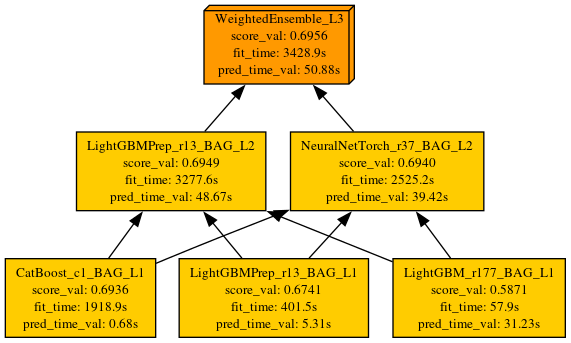

In [169]:
predictor.plot_ensemble_model(filename='ensemble_model.png')
display(Image(f'{MODELS_PATH}ensemble_model.png'))

In [170]:
## -- Extract model scores --
result_df = leaderboard[['model', 'score_val']]

max_score = result_df['score_val'].max()
min_score = result_df['score_val'].min()

result_df

,model,score_val
0,WeightedEnsemble_L3,0.695624
1,LightGBMPrep_r13_BAG_L2,0.694870
2,NeuralNetTorch_r37_BAG_L2,0.694000
3,CatBoost_c1_BAG_L2,0.693923
4,CatBoost_c1_BAG_L1,0.693592
5,WeightedEnsemble_L2,0.693592
6,LightGBM_r177_BAG_L2,0.693538
7,LightGBM_r163_BAG_L2,0.692098
8,LightGBMPrep_r13_BAG_L1,0.674081
9,LightGBM_r177_BAG_L1,0.587054


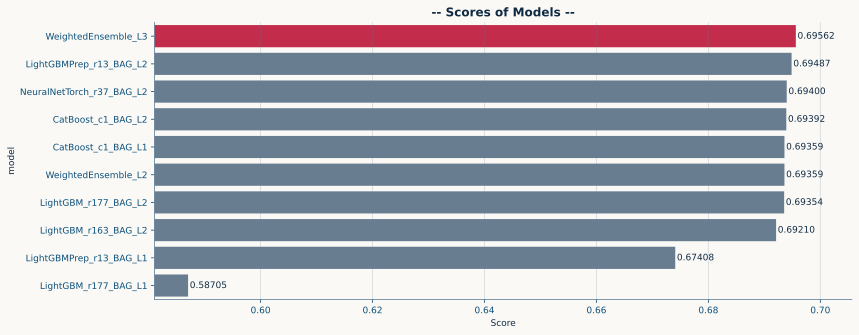

In [171]:
## -- Plot model scores --
plt.figure(figsize=(12.5, len(result_df)*0.5))
# plt.stem(
#     result_df.index,
#     result_df[0],
#     orientation = 'horizontal',
#     bottom = min_score - 0.0055,
#     markerfmt = 'C3o'
# )

sns.barplot(
    result_df, x=result_df['score_val'], y=result_df['model'], #width=0.5,
    palette=[MUTED if c < max_score else CRIM for c in result_df['score_val']]
)
plt.xlim(min_score - 0.006, max_score + 0.01)
plt.xlabel('Score')
plt.title('-- Scores of Models --')

for i, value in enumerate(result_df['score_val']):
    plt.text(value+3e-4, i, f'{abs(value):.5f}', ha='left', va='center')

plt.grid(True, axis='x')
# plt.tight_layout()
plt.show()

In [172]:
# predictor.model_names()

In [173]:
# ## -- Permutation Feature Importances --
# feat_imp = predictor.feature_importance(
#                         data = X_test,
#                         # time_limit = 3600,
#                         # model = 'LightGBM_BAG_L1',
#                         # features = None,
#                         # feature_stage = 'transformed',
#                         # subsample_size = 5000,
#                         # num_shuffle_sets = 10,
#                         # include_confidence_band = True,
#                         confidence_level = 0.95,
#                         # silent = False
# ) 

# feat_imp.style.background_gradient(subset=["importance"], cmap="Spectral")

# plt.figure(figsize=(18, 35))
# sns.barplot(data=feat_imp, y=feat_imp.index, x=feat_imp.importance)
# plt.tick_params(axis='y', which='major', labelcolor='r')
# plt.title("Top Features by Permutation")
# plt.tight_layout()
# plt.show()

In [174]:
print(f"""
{'-'*48}
{'█'*5} | - AUTOGLUON NOTEBOOK COMPLETE! - | {'█'*5}
{'-'*48}
""")


------------------------------------------------
█████ | - AUTOGLUON NOTEBOOK COMPLETE! - | █████
------------------------------------------------



In [175]:
## -- OPTIONAL: Clear stored files in memory --
!rm -r {MODELS_PATH}
print("⚙️ All models deleted!")

⚙️ All models deleted!


In [176]:
# !rm -r /kaggle/working